# HeLa raw images to Ultrack tracks

This notebook develops the raw-image workflow interactively on a small subset of `Fluo-N2DL-HeLa`. It keeps the main Ultrack stages separate so that the foreground and contour inputs can be checked before linking and solving.

Initial subset: sequence `01`, frames 12–16. Frame 12 has a gold-segmentation annotation, making it useful for visual inspection. Once the workflow is satisfactory, use a new run name and expand to the complete sequence.

The initial segmentation baseline uses Ultrack's `detect_foreground` and `robust_invert` image-processing utilities. This verifies that the pipeline begins with raw microscopy images, but it is not a direct reproduction of the published Cellpose, StarDist, watershed, or ensemble results.


## Environment and paths

The notebook reads shared data in place and writes generated artifacts only to the personal Ultrack run directory.

These variables are set before starting the VS Code notebook kernel, or in a temporary notebook cell before running the configuration cell:

```bash
export CTC_ROOT=/path/to/shared/ctc
export ULTRACK_RUN_ROOT=/path/to/personal/runs/ultrack
```


In [ ]:
CTC_ROOT = "<PROJECT_DATA_ROOT>/DSC_CTC"
ULTRACK_RUN_ROOT = "/<PROJECT_DATA_ROOT>/runs/ultrack"

In [2]:
import os
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage as ndi
from ultrack import MainConfig, Tracker
from ultrack.imgproc import detect_foreground, robust_invert

from cell_tracking.ultrack_2d import find_label_boundaries

print(f"Python: {sys.version.split()[0]}")
print(f"Ultrack: {version('ultrack')}")
print(f"Python executable: {sys.executable}")

Python: 3.12.15
Ultrack: 0.8.0
Python executable: <MICROMAMBA_ROOT>/envs/cell-tracking-ultrack/bin/python


In [3]:
os.environ["CTC_ROOT"] = CTC_ROOT
os.environ["ULTRACK_RUN_ROOT"] = ULTRACK_RUN_ROOT

In [4]:
ctc_root_value = os.environ.get("CTC_ROOT")
run_root_value = os.environ.get("ULTRACK_RUN_ROOT")

if not ctc_root_value:
    raise RuntimeError("Set CTC_ROOT before running this notebook.")
if not run_root_value:
    raise RuntimeError("Set ULTRACK_RUN_ROOT before running this notebook.")

CTC_ROOT = Path(ctc_root_value).expanduser()
ULTRACK_RUN_ROOT = Path(run_root_value).expanduser()

if not CTC_ROOT.is_dir():
    raise FileNotFoundError(f"CTC root does not exist: {CTC_ROOT}")

print(f"CTC root: {CTC_ROOT}")
print(f"Ultrack run root: {ULTRACK_RUN_ROOT}")

CTC root: <CTC_ROOT>
Ultrack run root: <ULTRACK_RUN_ROOT>


## Dataset subset and segmentation parameters

- `FRAME_STOP` is exclusive, following normal Python slicing. 

- Change `RUN_NAME` whenever the subset or parameters change so that separate experiments are not mixed.


### Selected Parameters

These values are not from the ECCV paper. They are the default settings of Ultrack 0.8.0’s raw-image utilities. We are using them as a reproducible starting point that still needs validation for HeLa. The published HeLa experiment instead used watershed, Cellpose, StarDist, and their ensemble.

| Parameter | Meaning | Effect of changing it |
|---|---|---|
| `FOREGROUND_SIGMA = 15.0` | Spatial scale used by `detect_foreground` to estimate slowly varying background. With no voxel size supplied, it is approximately in pixels. | Larger values produce a smoother, broader background estimate. Smaller values follow local intensity changes more closely and may remove parts of cells as background. |
| `REMOVE_HIST_MODE = False` | Whether to remove the most common intensity value before calculating the automatic Otsu threshold. | `True` can help when a large, uniform background dominates the intensity histogram. `False` leaves the histogram unchanged. |
| `MIN_FOREGROUND = 0.0` | An additional minimum intensity requirement after background subtraction and smoothing. | `0.0` imposes no extra positive cutoff, leaving the automatic threshold to do the selection. Raising it rejects dimmer foreground, potentially removing faint nuclei. |
| `CONTOUR_SIGMA = 1.0` | Gaussian smoothing applied by `robust_invert` before the image is normalized and inverted to create the contour map. | Larger values suppress noise but can blur boundaries between nearby nuclei. Smaller values preserve fine boundaries but may create noisy segmentation hypotheses. |

In [ ]:
DATASET = "Fluo-N2DL-HeLa"
SEQUENCE = "01"
FRAME_START = 12
FRAME_STOP = 17

FOREGROUND_SIGMA = 15.0
REMOVE_HIST_MODE = False
MIN_FOREGROUND = 0.0
CONTOUR_SIGMA = 1.0

RUN_NAME = "hela-seq01-t012-016-auto-fg15-contour1"

DATASET_ROOT = CTC_ROOT / "ctc" / DATASET
RAW_DIR = DATASET_ROOT / SEQUENCE
GT_SEG_DIR = DATASET_ROOT / f"{SEQUENCE}_GT/SEG"
RUN_DIR = ULTRACK_RUN_ROOT / RUN_NAME

print(f"Raw input: {RAW_DIR}")
print(f"Sparse GT reference: {GT_SEG_DIR}")
print(f"Run output: {RUN_DIR}")

## Load raw microscopy images

Only files from the raw sequence folder are loaded. Nothing under `GT`, `ST`, or `ERR_SEG` is used to construct the segmentation inputs.


In [6]:
all_raw_paths = sorted(RAW_DIR.glob("t*.tif"))
raw_paths = all_raw_paths[FRAME_START:FRAME_STOP]

if len(raw_paths) != FRAME_STOP - FRAME_START:
    raise ValueError(
        f"Expected {FRAME_STOP - FRAME_START} raw frames, "
        f"but found {len(raw_paths)}."
    )

raw_images = np.stack([tifffile.imread(path) for path in raw_paths])
frame_numbers = [int(path.stem.removeprefix("t")) for path in raw_paths]

print(f"Files: {raw_paths[0].name} to {raw_paths[-1].name}")
print(f"Array shape: {raw_images.shape}")
print(f"Data type: {raw_images.dtype}")
print(f"Intensity range: {raw_images.min()} to {raw_images.max()}")

Files: t012.tif to t016.tif
Array shape: (5, 700, 1100)
Data type: uint16
Intensity range: 33001 to 36863


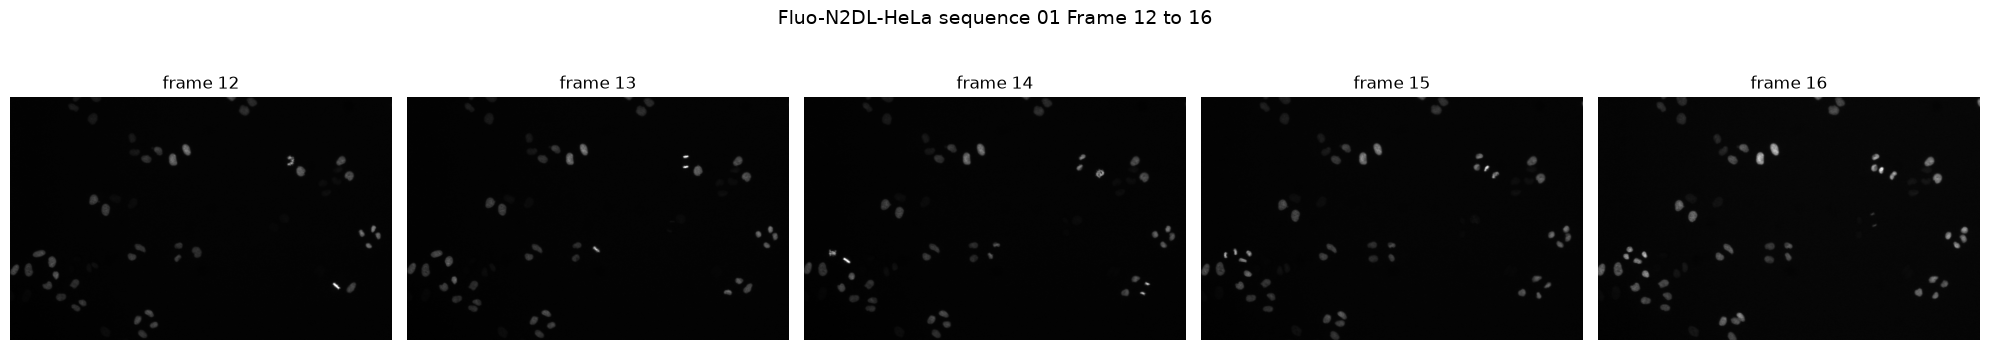

In [7]:
START_FRAME, END_FRAME = 12, 17  # end exclusive

# Map frame numbers to positions in raw_images
display_indices = [
    i for i, f in enumerate(frame_numbers) if START_FRAME <= f < END_FRAME
]

fig, axes = plt.subplots(1, len(display_indices), figsize=(4 * len(display_indices), 4))
axes = [axes] if len(display_indices) == 1 else axes

for ax, idx in zip(axes, display_indices):
    ax.imshow(raw_images[idx], cmap="gray")
    ax.set_title(f"frame {frame_numbers[idx]}")
    ax.axis("off")

fig.suptitle(f"{DATASET} sequence {SEQUENCE} Frame 12 to 16", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
fig.savefig(
    "../../docs/images/foreground-contours.png",
    dpi=150,
    bbox_inches="tight",
)

## Create foreground and contour maps from raw images

Ultrack requires two canonical inputs with the same `(time, y, x)` shape:

- `foreground`: where cells may be present;
- `contours`: confidence that pixels belong to cell boundaries.

Each frame is processed independently so the Gaussian filters do not smooth across time. Ground truth is not used in either calculation.

- The foreground is mapped using the `detect_foreground` function from Ultrack's image processing `ultrack.imgproc`
- The contours (which is the confidence that the pixel belongs to the cell boundaries) is mapped using the `robust_invert` funtion from Ultrack's image processing `ultrack.imgproc`


In [8]:
foreground = np.stack(
    [
        np.asarray(
            detect_foreground(
                frame,
                sigma=FOREGROUND_SIGMA,
                remove_hist_mode=REMOVE_HIST_MODE,
                min_foreground=MIN_FOREGROUND,
            )
        )
        for frame in raw_images
    ]
).astype(bool)

contours = np.stack(
    [np.asarray(robust_invert(frame, sigma=CONTOUR_SIGMA)) for frame in raw_images]
).astype(np.float32)

if foreground.shape != raw_images.shape or contours.shape != raw_images.shape:
    raise ValueError("Raw, foreground, and contour shapes must match.")

print(f"Foreground shape and dtype: {foreground.shape}, {foreground.dtype}")
print(f"Contour shape and dtype: {contours.shape}, {contours.dtype}")

Foreground shape and dtype: (5, 700, 1100), bool
Contour shape and dtype: (5, 700, 1100), float32


In [9]:
segmentation_input_summary = pd.DataFrame(
    {
        "frame": frame_numbers,
        "foreground fraction": foreground.mean(axis=(1, 2)),
        "contour minimum": contours.min(axis=(1, 2)),
        "contour maximum": contours.max(axis=(1, 2)),
        "contour mean": contours.mean(axis=(1, 2)),
    }
)
segmentation_input_summary

,frame,foreground fraction,contour minimum,contour maximum,contour mean
0,12,0.026448,0.0,0.074888,0.072899
1,13,0.026156,0.0,0.074858,0.072890
2,14,0.026410,0.0,0.078667,0.076677
3,15,0.029171,0.0,0.059711,0.057691
4,16,0.026671,0.0,0.053492,0.051373


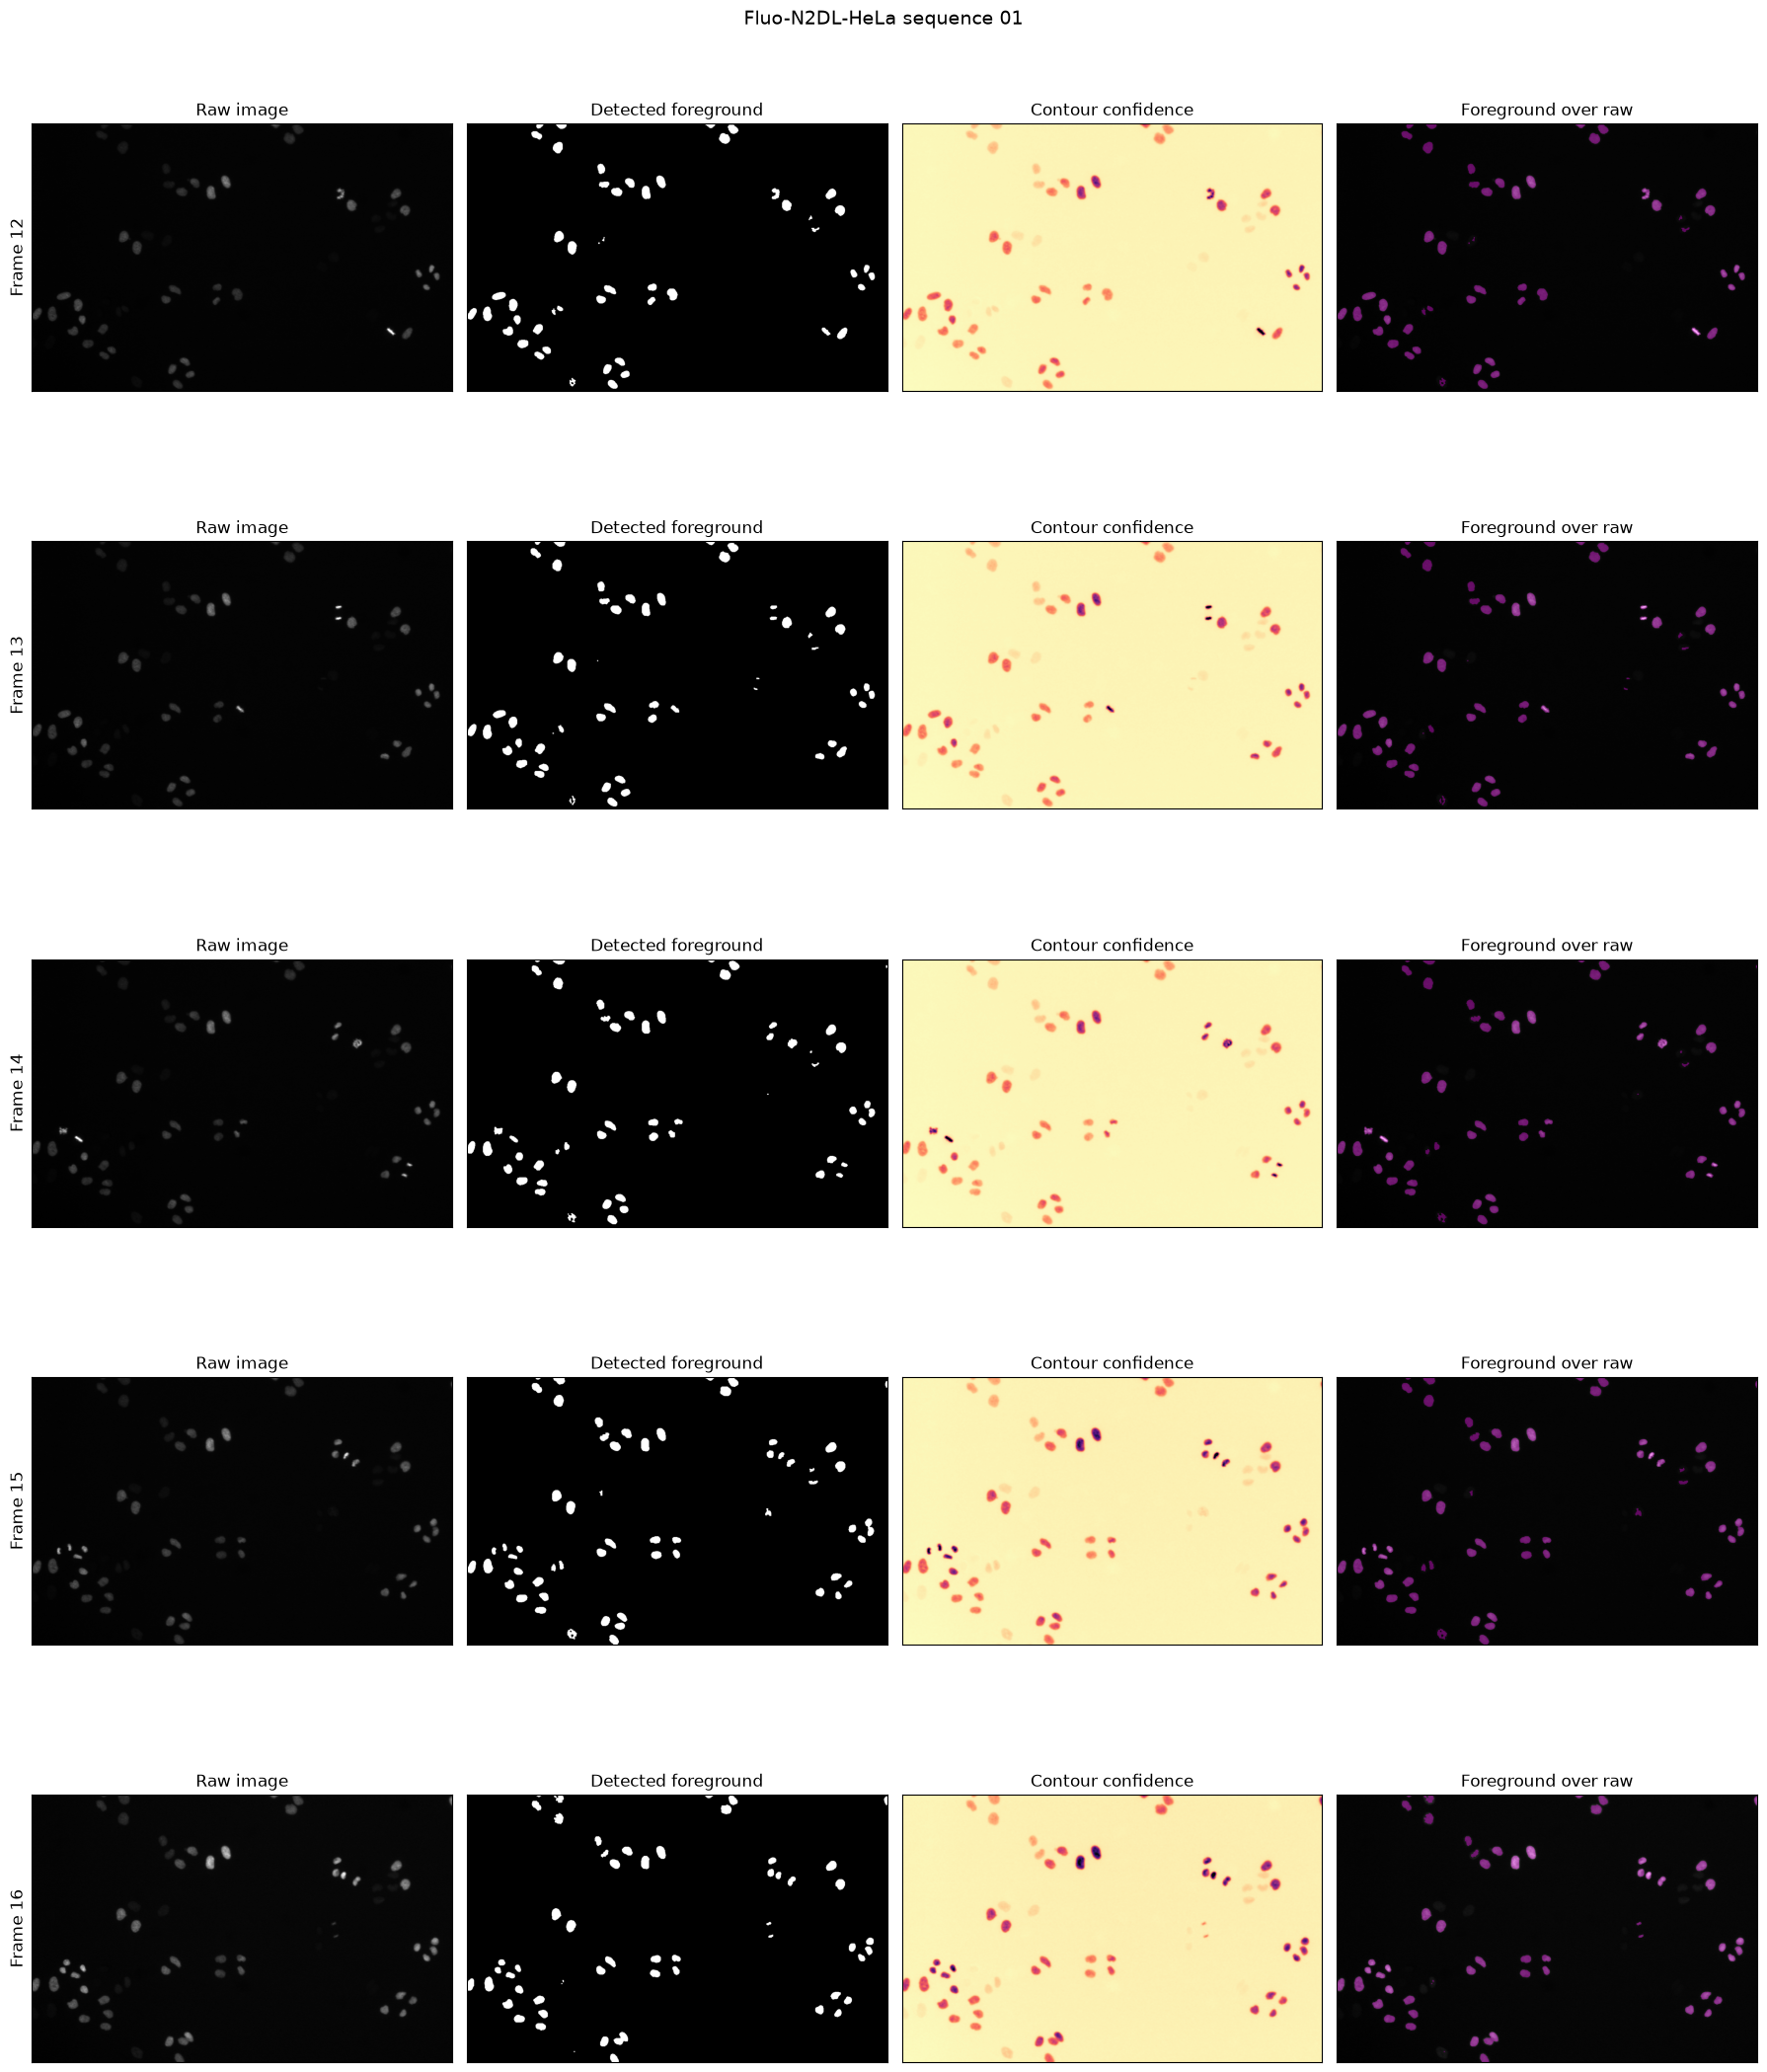

In [35]:
START_FRAME, END_FRAME = 12, 17  # end exclusive

display_indices = [
    i for i, f in enumerate(frame_numbers) if START_FRAME <= f < END_FRAME
]
n_rows = len(display_indices)

figure, axes = plt.subplots(n_rows, 4, figsize=(18, 4.5 * n_rows), squeeze=False)

for row, idx in zip(axes, display_indices):
    image = raw_images[idx]
    mask = foreground[idx].astype(bool)
    contour = contours[idx]

    row[0].imshow(image, cmap="gray")
    row[0].set_title("Raw image")
    row[1].imshow(mask, cmap="gray")
    row[1].set_title("Detected foreground")
    row[2].imshow(contour, cmap="magma")
    row[2].set_title("Contour confidence")
    row[3].imshow(image, cmap="gray")
    row[3].imshow(np.ma.masked_where(~mask, mask), cmap="spring", alpha=0.35)
    row[3].set_title("Foreground over raw")

    row[0].set_ylabel(f"Frame {frame_numbers[idx]}", fontsize=12)
    for axis in row:
        axis.set_xticks([])
        axis.set_yticks([])

figure.suptitle(f"{DATASET} sequence {SEQUENCE}", fontsize=14)
plt.tight_layout()
plt.show()

In [36]:
output_path = Path("../../docs/images/foreground-contours.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_path, dpi=150, bbox_inches="tight")

## Comparison with sparse gold segmentation

Gold segmentation is used only to inspect the foreground map. It is not passed to Ultrack. Because the gold mask contains selected manually annotated cells rather than exhaustive background labels, the notebook reports the fraction of annotated cell pixels captured by the foreground but does not treat every unlabeled pixel as true background.


No gold-segmentation file exists for frame 16.
Frame 12: 2 annotated cells; label IDs = [9, 55]
Frame 13: 59 annotated cells; label IDs = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
Frame 14: 4 annotated cells; label IDs = [1, 2, 9, 55]
Frame 15: 8 annotated cells; label IDs = [1, 2, 3, 4, 5, 6, 7, 8]


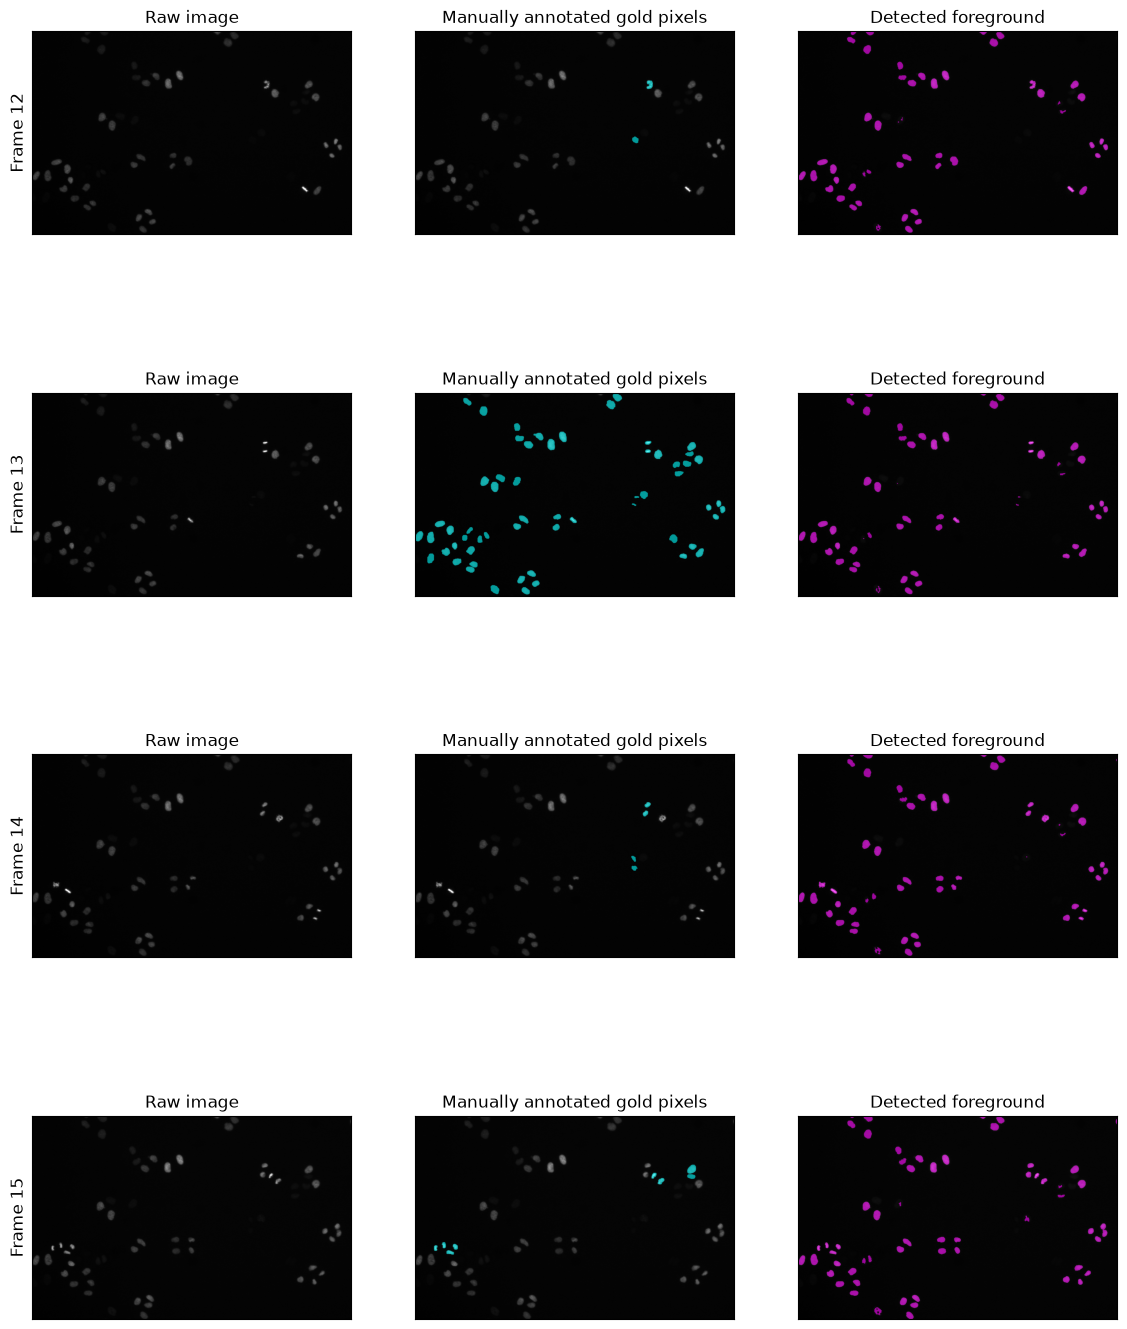

In [33]:
START_FRAME, END_FRAME = 12, 17  # end exclusive

display_indices = [
    i for i, f in enumerate(frame_numbers) if START_FRAME <= f < END_FRAME
]

# Keep only frames that have a gold-segmentation file
rows = []
for idx in display_indices:
    frame = frame_numbers[idx]
    gt_path = GT_SEG_DIR / f"man_seg{frame:03d}.tif"
    if gt_path.is_file():
        rows.append((idx, frame, gt_path))
    else:
        print(f"No gold-segmentation file exists for frame {frame}.")

if rows:
    figure, axes = plt.subplots(
        len(rows), 3, figsize=(14, 4.5 * len(rows)), squeeze=False
    )
    coverages = {}

    for row, (idx, frame, gt_path) in zip(axes, rows):
        image = raw_images[idx]
        mask = foreground[idx].astype(bool)

        gt_labels = tifffile.imread(gt_path)

        label_ids = np.unique(gt_labels)
        label_ids = label_ids[label_ids != 0]

        print(
            f"Frame {frame}: {len(label_ids)} annotated cells; "
            f"label IDs = {label_ids.tolist()}"
        )

        gt_mask = gt_labels > 0
        coverages[frame] = mask[gt_mask].mean()

        gold_overlay = np.ma.masked_where(
            ~gt_mask,
            np.ones_like(gt_mask, dtype=np.uint8),
        )

        row[0].imshow(image, cmap="gray")
        row[0].set_title("Raw image")
        row[1].imshow(image, cmap="gray")
        row[1].imshow(
            np.ma.masked_where(~gt_mask, gt_labels),
            cmap="tab20",
            alpha=0.6,
        )

        row[1].imshow(image, cmap="gray")
        row[1].imshow(
            gold_overlay,
            cmap=ListedColormap(["cyan"]),
            alpha=0.6,
        )
        row[1].set_title("Manually annotated gold pixels")

        row[2].imshow(image, cmap="gray")
        row[2].imshow(
            np.ma.masked_where(~mask, mask),
            cmap=ListedColormap(["fuchsia"]),
            alpha=0.6,
        )
        row[2].set_title("Detected foreground")

        row[0].set_ylabel(f"Frame {frame}", fontsize=12)
        for axis in row:
            axis.set_xticks([])
            axis.set_yticks([])

In [34]:
output_path = Path("../../docs/images/foreground-contours-gold-comparison.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_path, dpi=150, bbox_inches="tight")

### Per-gold-object coverage and IoU

In [12]:
MIN_GOLD_COVERAGE = 0.5
object_records = []

for idx, frame, gt_path in rows:
    gold_labels = tifffile.imread(gt_path)
    detected_mask = foreground[idx].astype(bool)

    detected_labels, _ = ndi.label(detected_mask)

    gold_ids = np.unique(gold_labels)
    gold_ids = gold_ids[gold_ids != 0]

    for gold_id in gold_ids:
        gold_object = gold_labels == gold_id
        gold_area = int(gold_object.sum())

        component_ids, overlap_counts = np.unique(
            detected_labels[gold_object],
            return_counts=True,
        )

        # Component 0 is background, not a detected object.
        nonbackground = component_ids != 0
        component_ids = component_ids[nonbackground]
        overlap_counts = overlap_counts[nonbackground]

        if len(component_ids) == 0:
            best_component = 0
            intersection = 0
            detected_area = 0
            iou = 0.0
        else:
            best_position = int(np.argmax(overlap_counts))
            best_component = int(component_ids[best_position])
            intersection = int(overlap_counts[best_position])

            detected_object = detected_labels == best_component
            detected_area = int(detected_object.sum())
            union = gold_area + detected_area - intersection
            iou = intersection / union

        coverage = intersection / gold_area

        object_records.append(
            {
                "frame": frame,
                "gold label": int(gold_id),
                "gold area": gold_area,
                "detected component": best_component,
                "detected area": detected_area,
                "gold coverage": coverage,
                "IoU": iou,
                "covered at 50%": coverage >= MIN_GOLD_COVERAGE,
            }
        )

object_results = pd.DataFrame(object_records)
display(object_results)

,frame,gold label,gold area,detected component,detected area,gold coverage,IoU,covered at 50%
0,12,9,482,14,410,0.834025,0.820408,True
1,12,55,383,0,0,0.000000,0.000000,False
2,13,1,481,5,433,0.893971,0.888430,True
3,13,2,709,7,605,0.853315,0.853315,True
4,13,3,464,8,403,0.868534,0.868534,True
...,...,...,...,...,...,...,...,...
68,15,4,248,18,197,0.794355,0.794355,True
69,15,5,290,39,224,0.768966,0.766323,True
70,15,6,272,34,229,0.838235,0.835165,True
71,15,7,229,33,181,0.777293,0.767241,True


In [13]:
frame_summary = object_results.groupby("frame", as_index=False).agg(
    annotated_objects=("gold label", "count"),
    objects_covered_50pct=("covered at 50%", "sum"),
    mean_gold_coverage=("gold coverage", "mean"),
    median_gold_coverage=("gold coverage", "median"),
    median_iou=("IoU", "median"),
)

display(frame_summary)

,frame,annotated_objects,objects_covered_50pct,mean_gold_coverage,median_gold_coverage,median_iou
0,12,2,1,0.417012,0.417012,0.410204
1,13,59,44,0.637004,0.816129,0.816129
2,14,4,2,0.452406,0.439560,0.428571
3,15,8,7,0.712441,0.804089,0.801132


### Boundary overlay

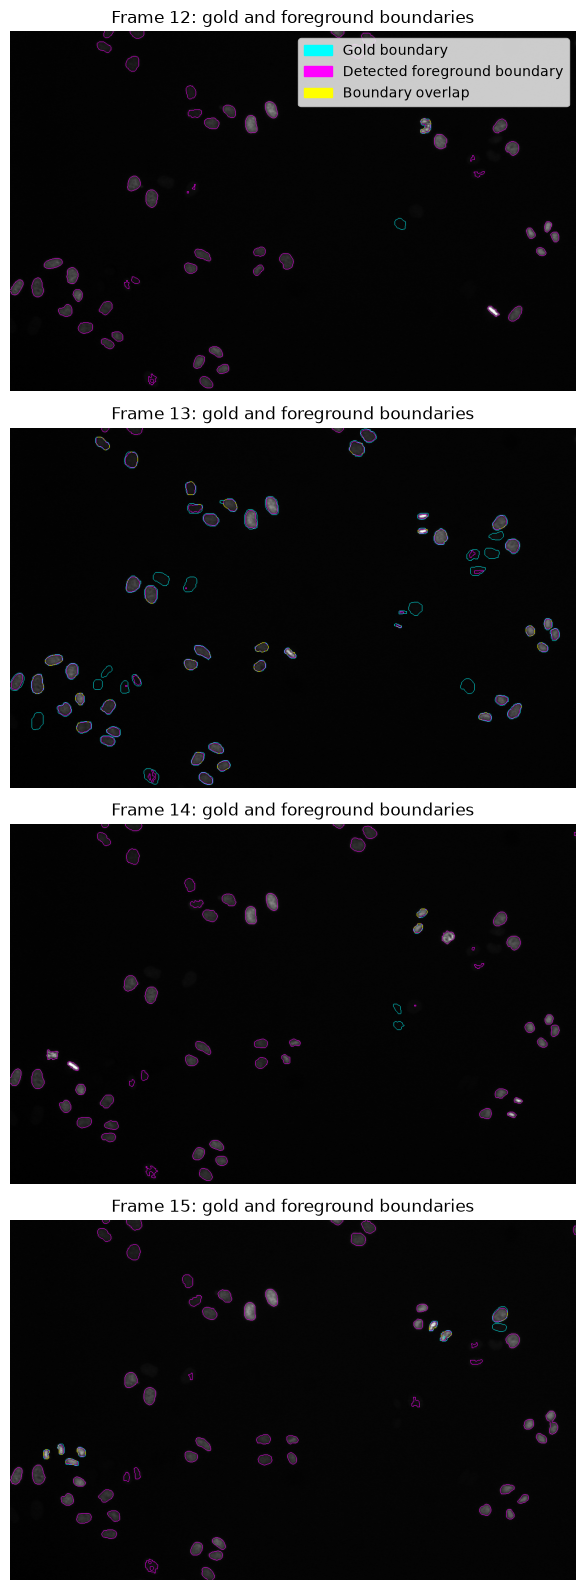

In [31]:
figure, axes = plt.subplots(
    len(rows),
    1,
    figsize=(12, 4 * len(rows)),
    squeeze=False,
)

for axis, (idx, frame, gt_path) in zip(axes[:, 0], rows):
    image = raw_images[idx]
    gold_labels = tifffile.imread(gt_path)

    detected_labels, _ = ndi.label(foreground[idx].astype(bool))

    gold_boundary = find_label_boundaries(gold_labels)
    detected_boundary = find_label_boundaries(detected_labels)
    overlapping_boundary = gold_boundary & detected_boundary

    overlay = np.zeros((*image.shape, 4), dtype=float)
    overlay[detected_boundary] = (1.0, 0.0, 1.0, 0.9)
    overlay[gold_boundary] = (0.0, 1.0, 1.0, 0.9)
    overlay[overlapping_boundary] = (1.0, 1.0, 0.0, 1.0)

    axis.imshow(image, cmap="gray")
    axis.imshow(overlay)
    axis.set_title(f"Frame {frame}: gold and foreground boundaries")
    axis.axis("off")

legend_items = [
    Patch(color="cyan", label="Gold boundary"),
    Patch(color="magenta", label="Detected foreground boundary"),
    Patch(color="yellow", label="Boundary overlap"),
]
axes[0, 0].legend(handles=legend_items, loc="upper right")

plt.tight_layout()
plt.show()

**What the gold boundary overlay shows**

- Cyan: Gold Boundary
- Magenta: Detected Foreground Boundary
- Yellow: Boundary overlay

**What the gold boundary overlay shows**
1. Cyan with no nearby magenta: foreground probably missed part of an annotated cell.

- This is obsereved in all 3 frames, with the clearest one showing in frame 12 and many other cases in frame 13

2. Magenta substantially outside cyan: foreground is larger than the annotated object, although it might include valid unannotated cells.

- A few cases of this are obsereved in frame 13 towards the right

3. One large magenta region around multiple cyan objects: foreground merged neighboring cells; inspect whether the contour map provides boundaries Ultrack can use.

- No such case in the selected frames

In [32]:
output_path = Path("../../docs/images/gold-boundaries-overlay.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_path, dpi=150, bbox_inches="tight")

## Configure Ultrack

The following cells run segmentation, linking, and solving separately. They use only the raw-derived foreground and contour maps. `overwrite=True` replaces the Ultrack database content inside this run directory, so change `RUN_NAME` before testing a different experiment that should be retained.


In [ ]:
RUN_DIR.mkdir(parents=True, exist_ok=True)

N_WORKERS = 4

config = MainConfig()
config.data_config.working_dir = RUN_DIR

config.data_config.n_workers = 1
config.segmentation_config.n_workers = 4
config.linking_config.n_workers = 1
config.tracking_config.n_threads = 4

config.tracking_config.solver_name = "GUROBI"

print(config)

data_config=DataConfig(n_workers=4, working_dir=PosixPath('<ULTRACK_RUN_ROOT>/hela-seq01-t012-016-auto-fg15-contour1'), database_file_name='data.db', database='sqlite', address=None, in_memory_db_id=0) segmentation_config=SegmentationConfig(min_area=100, min_area_factor=4.0, max_area=1000000, n_workers=4, min_frontier=0.0, threshold=0.5, max_noise=0.0, random_seed='frame', ws_hierarchy=<function watershed_hierarchy_by_area at 0x760f9b449f80>, anisotropy_penalization=0.0) linking_config=LinkingConfig(max_distance=15.0, n_workers=4, max_neighbors=5, distance_weight=0.0, z_score_threshold=5.0) tracking_config=TrackingConfig(solver_name='GUROBI', appear_weight=-0.001, disappear_weight=-0.001, division_weight=-0.001, image_border_size=None, n_threads=4, window_size=None, overlap_size=1, solution_gap=0.001, time_limit=36000, method=0, link_function='power', power=4, bias=-0.0, dismiss_weight_guess=None, include_weight_guess=None)


## Create segmentation hypotheses

Run this cell only after the inspection checkpoint is satisfactory. 

This is Ultrack's segmentation stage; it creates candidate regions based on the foreground and contour maps in the run database. Unlike other methodologies, it creates multiple segmentation hypothesis rather than a single one.


In [16]:
tracker = Tracker(config=config)
tracker.segment(
    foreground=foreground,
    contours=contours,
    overwrite=True,
)
print("Segmentation stage complete.")

Adding nodes to database: 100%|██████████| 5/5 [07:12<00:00, 86.56s/it] 


Segmentation stage complete.


## Link candidate segments


In [18]:
tracker.config.data_config.n_workers = 1
tracker.config.linking_config.n_workers = 1

print(
    "Linking workers:",
    tracker.config.linking_config.n_workers,
)

tracker.link(overwrite=True)
print("Linking stage complete.")

Linking workers: 1


Linking nodes.: 100%|██████████| 4/4 [00:04<00:00,  1.19s/it]

Linking stage complete.


## Solve the tracking problem

This stage uses the configured Gurobi solver to select a temporally consistent set of segments and links.


In [ ]:
tracker.solve()
print("Solving stage complete.")

## Export and inspect the subset result


In [ ]:
tracks, graph = tracker.to_tracks_layer()
tracks_path = RUN_DIR / "tracks.csv"
segments_path = RUN_DIR / "segments.zarr"
ctc_output_dir = RUN_DIR / f"{SEQUENCE}_RES"

tracks.to_csv(tracks_path, index=False)
segments = tracker.to_zarr(
    store_or_path=segments_path,
    overwrite=True,
)
tracker.to_ctc(
    ctc_output_dir,
    overwrite=True,
)

print(f"Track rows: {len(tracks)}")
print(f"Unique tracks: {tracks['track_id'].nunique()}")
print(f"Lineage graph entries: {len(graph)}")
print(f"Tracks CSV: {tracks_path}")
print(f"Segments: {segments_path}")
print(f"CTC subset output: {ctc_output_dir}")

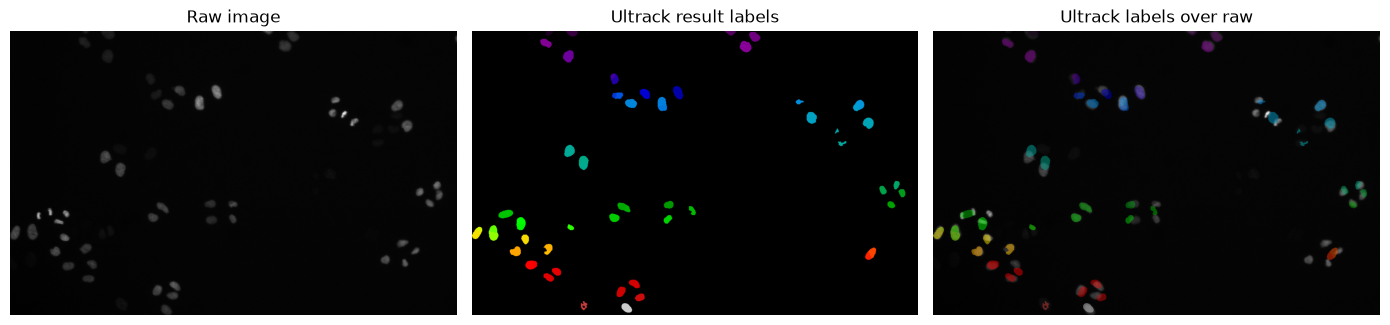

In [23]:
result_labels = np.asarray(segments)

DISPLAY_LOCAL_INDEX = 0

figure, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Raw image")
axes[1].imshow(result_labels[DISPLAY_LOCAL_INDEX], cmap="nipy_spectral")
axes[1].set_title("Ultrack result labels")
axes[2].imshow(image, cmap="gray")
axes[2].imshow(
    np.ma.masked_where(
        result_labels[DISPLAY_LOCAL_INDEX] == 0,
        result_labels[DISPLAY_LOCAL_INDEX],
    ),
    cmap="nipy_spectral",
    alpha=0.5,
)
axes[2].set_title("Ultrack labels over raw")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
output_path = Path("../../docs/images/ultrack-labels-over-rows.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_path, dpi=150, bbox_inches="tight")

### Initial five-frame Ultrack experiment

- Dataset: `Fluo-N2DL-HeLa`, sequence `01`
- Original frames: 12–16
- Image shape: `(700, 1100)`
- Ultrack version: 0.8.0
- Foreground parameters:
  - `FOREGROUND_SIGMA = 15.0`
  - `REMOVE_HIST_MODE = False`
  - `MIN_FOREGROUND = 0.0`
  - `CONTOUR_SIGMA = 1.0`
- Worker configuration:
  - segmentation: 4 workers
  - linking: 1 worker
  - Gurobi: 4 threads
- Segmentation runtime: approximately 7 minutes 12 seconds
- Linking runtime: approximately 4 seconds
- Gurobi optimization: approximately 0.5 seconds, excluding model construction
- Output:
  - 329 track rows
  - 88 unique tracks
  - 16 lineage graph entries

Parallel segmentation completed successfully. Parallel linking failed with
`sqlite3.OperationalError: database is locked` because the SQLite database was
stored on shared `/net` storage. Linking succeeded with one worker. This worker
configuration should be retained while the database remains on shared storage.

This is an exploratory five-frame run, not a final benchmark. CTC output frame
`000` corresponds to original raw frame `012`.